# Kasese Micro-grid Analysis

The OOP classes live in `src/microgrid.py`; data input, analysis, reporting, and plotting live in `src/microgrid_analysis.py`. This notebook imports and uses those modules rather than copying their implementation.

Run cells from top to bottom. The seeded 30-day CSV is loaded if present and generated if missing.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.microgrid import HybridMicroGrid, MicroGrid
from src.microgrid_analysis import (
    run_interactive_mode,
    run_microgrid_analysis,
)

In [2]:
grid = MicroGrid()
hybrid_grid = HybridMicroGrid()

print('Base coefficient matrix:')
print(grid.coefficients)
print(f'Determinant: {grid.determinant:.3f}')
print(f'2-norm condition number: {grid.condition_number:.3f}')
print('Base dispatch for D1=80, D2=45:', grid.solve_day(80, 45))
print('Hybrid dispatch for D1=80, D2=45, D3=50:', hybrid_grid.solve_day(80, 45, 50))

Base coefficient matrix:
[[3. 2.]
 [4. 1.]]
Determinant: -5.000
2-norm condition number: 5.828
Base dispatch for D1=80, D2=45: [ 2. 37.]
Hybrid dispatch for D1=80, D2=45, D3=50: [-6.25 42.5  13.75]


## Well-posedness and feasibility

For the base coefficient matrix `[[3, 2], [4, 1]]`, determinant `-5` is nonzero, so each valid demand pair has a unique exact solution; `scipy.linalg.solve` solves this square system [1]. The 2-norm condition number is about `5.83`; it measures worst-direction relative error amplification [2], not the error expected for every day.

A negative exact solar or battery value is physically infeasible. The analysis flags that day and applies non-negative least squares (NNLS), which minimizes squared residual subject to nonnegative source values [3]. The reported residual matters because the adjusted dispatch may no longer satisfy both equations exactly. The interactive entry point re-prompts on empty, nonnumeric, negative, or non-finite demand input; call `run_interactive_mode()` in a separate cell when prompted input is desired.

In [3]:
results = run_microgrid_analysis(monte_carlo_draws=1000)
print(f"Loaded {len(results['data'])} days")
print(f"Flagged infeasible days: {len(results['infeasible_days'])}")
print(f"Monthly total cost: UGX {results['monthly_cost_UGX']:,.0f}")

Loaded 30 days
Flagged infeasible days: 15
Monthly total cost: UGX 543,741


In [4]:
print('Determinant:', results['determinant'])
print('Condition number:', results['condition_number'])
print('Timing:', results['timing'])
print('Source statistics:')
print(pd.DataFrame(results['statistics']).T.to_string())
print('Monte Carlo sensitivity:')
print(results['sensitivity'])

Determinant: -4.999999999999999
Condition number: 5.82842712474619
Timing: {'loop_seconds_per_batch': 0.001939869998022914, 'vectorized_seconds_per_batch': 9.29799978621304e-05, 'speedup': 20.863304394772406, 'repeats': 5, 'number_per_repeat': 10}
Source statistics:
                         mean_kWh variance_kWh2 stdev_kWh coefficient_of_variation
solar                    0.303073      0.167184  0.408882                 1.349118
battery                 40.176073      8.531411  2.920858                 0.072701
more_volatile_by_stdev    battery       battery   battery                  battery
more_volatile_by_cv         solar         solar     solar                    solar
Monte Carlo sensitivity:
{'draws': 1000, 'perturbation_fraction': 0.05, 'baseline_demands_kWh': array([81.4703, 40.9705]), 'baseline_dispatch_kWh': array([ 0.09414, 40.59394]), 'mean_absolute_move_kWh': array([0.55615505, 1.7029525 ]), 'p95_absolute_move_kWh': array([1.24173114, 3.58183142]), 'mean_absolute_move_perc

## Workflow and interpretation

The CSV has 30 seeded demand days with a weekly pattern and noise. Both the per-day Python loop and one vectorized SciPy solve are timed with `timeit`; at this small batch size, timings are machine-dependent, though vectorization avoids repeated Python-level calls. Daily cost uses UGX 150/kWh for solar and UGX 450/kWh for battery; the 30 daily costs are summed as the illustrative monthly cost.

The statistics report both absolute standard deviation and coefficient of variation: a source can be more volatile in absolute kWh but less volatile relative to its mean. Sensitivity perturbs both demands independently by +/-5% for 1,000 seeded draws.

The hybrid model adds diesel and a total-supply equation. If its new equation is linearly dependent on the other two, the determinant is zero and the condition number infinite; the three source values cannot be uniquely recovered.

In [5]:
results['data'][[
    'day', 'D1_kWh', 'D2_kWh', 'raw_solar_kWh', 'raw_battery_kWh',
    'physically_infeasible', 'solar_kWh', 'battery_kWh',
    'nnls_residual_kWh', 'daily_cost_UGX',
]]

,day,D1_kWh,D2_kWh,raw_solar_kWh,raw_battery_kWh,physically_infeasible,solar_kWh,battery_kWh,nnls_residual_kWh,daily_cost_UGX
0,1,82.670,44.212,1.1508,39.6088,False,1.1508,39.6088,0.000000,17996.58
1,2,82.712,42.390,0.4136,40.7356,False,0.4136,40.7356,0.000000,18393.06
2,3,88.651,43.232,-0.4374,44.9816,True,0.0000,44.1068,0.978056,19848.06
3,4,88.069,41.779,-0.9022,45.3878,True,0.0000,43.5834,2.017381,19612.53
4,5,78.708,41.924,1.0280,37.8120,False,1.0280,37.8120,0.000000,17169.60
5,6,71.135,38.693,1.2502,33.6922,False,1.2502,33.6922,0.000000,15349.02
6,7,72.281,35.829,-0.1246,36.3274,True,0.0000,36.0782,0.278614,16235.19
7,8,81.304,39.740,-0.3648,41.1992,True,0.0000,40.4696,0.815718,18211.32
8,9,84.963,41.763,-0.2874,42.9126,True,0.0000,42.3378,0.642646,19052.01
9,10,85.123,44.976,0.9658,41.1128,False,0.9658,41.1128,0.000000,18645.63


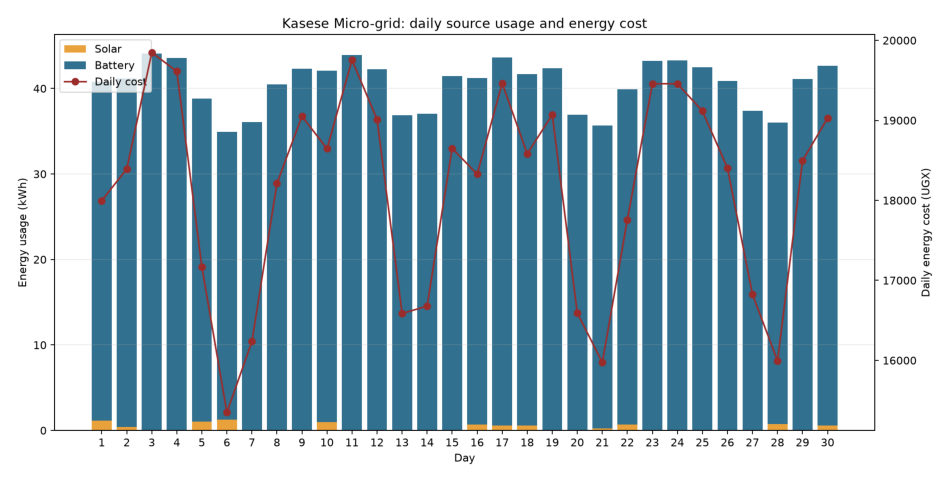

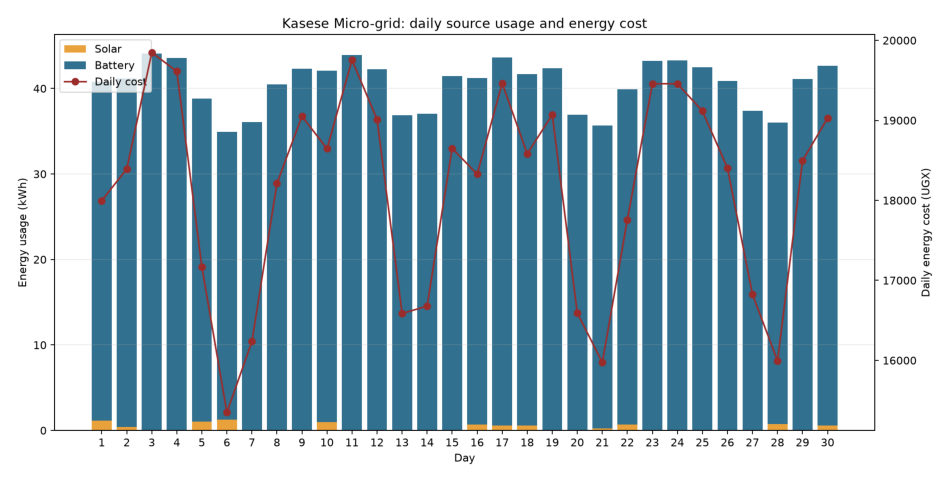

In [6]:
microgrid_figure, microgrid_axis = plt.subplots(figsize=(12, 6))
microgrid_axis.imshow(plt.imread(results['plot_path']))
microgrid_axis.axis('off')
microgrid_figure

## Findings & Limitations

The base system is uniquely solvable and not close to singular: determinant -5 and 2-norm condition number 5.83 indicate a moderate worst-direction sensitivity. Yet 15 of 30 generated days produce negative solar under the exact equations. This is a physical mismatch between the sampled loads and the model, not a solver failure. NNLS gives nonnegative dispatches, but the reported residual means both demand equations cannot then be met exactly; a real operator would need reserve capacity or explicit load-priority rules.

Battery use has greater absolute variation (standard deviation 2.92 kWh versus solar’s 0.41), while solar’s coefficient of variation is much larger (about 135% versus 7%). Solar’s high relative volatility is amplified by its near-zero mean, so it should not be read as a large absolute energy swing. In the seeded example, the 30-day illustrative cost is about UGX 543,741 and the vectorized solve is roughly an order of magnitude faster, but timing a batch this small is sensitive to machine load. Sensitivity results likewise reflect a near-zero baseline solar estimate; percentage movement becomes unstable there even when its kWh movement is small.

Most importantly, these demands are synthetic and represent only one month. The linear equations omit conversion losses, battery state of charge and capacity, solar availability, outages, and generator operating cost. The prices are illustrative. Validate with measured loads and equipment constraints before using the dispatch or cost figures operationally.